In [1]:
import matplotlib.pyplot as plt
import numpy as np


def plot_selection_result(results, ax, budget=None, label=None, color=None):
    import scipy.stats as sps

    if budget is None:
        budget = results.shape[-1]

    def ci(y):
        br = sps.bootstrap((y,), np.mean, vectorized=True)
        ci_l = br.confidence_interval.low
        ci_u = br.confidence_interval.high
        return ci_l, ci_u

    iters = np.arange(0, budget, 1)
    agg_value = results.mean(axis=0)[:budget].ravel()
    _ci_lb, _ci_ub = ci(results)[:budget]

    line, *_ = ax.plot(iters, agg_value, linewidth=1.5, label=label, color=color)

    ax.plot(iters, _ci_lb, linewidth=1.5, alpha=0.5, color=line.get_color())
    ax.plot(iters, _ci_ub, linewidth=1.5, alpha=0.5, color=line.get_color())
    ax.fill_between(iters, _ci_lb, _ci_ub, alpha=0.3, color=line.get_color())


# optuna and random

In [2]:
import torch
import numpy as np


def get_res_p(_path):
    arr = np.loadtxt(_path)
    return get_res_o(arr)

def get_res_o(arr):
    return torch.from_numpy(arr).cummax(axis=-1).values.detach().numpy()

In [3]:
# get random res

from tidyhebo.optimizers_reference import RealParameter, RealDesignSpace
from botorch.test_functions.synthetic import Ackley
import torch


problem = Ackley(dim=6, negate=True)


def get_random(problem):
    params = [
        RealParameter(i, lb, ub) for (i, (lb, ub)) in enumerate(problem.bounds.T.detach().numpy())
    ]
    ds = RealDesignSpace(params)

    # sample initial points
    n_init = 100
    x0 = torch.rand(n_init, len(params)).double()
    x0 = ds.to_domain_space(x0)
    y0 = problem(x0)
    
    return y0

random_out = np.array([get_random(problem) for i in range(30)])

random_res = get_res_o(random_out)


/home/jnarbert/miniforge3/envs/tidyhebo/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# get optuna res


from botorch.test_functions import Ackley

problem = Ackley(dim=6, negate=True)


from tidyhebo.optimizers_reference import OptunaOptimizer, RealParameter, RealDesignSpace


# RealParameter, RealDesignSpace

def get_optuna(problem):
    params = [
        RealParameter(i, lb, ub) for (i, (lb, ub)) in enumerate(problem.bounds.T.detach().numpy())
    ]
    ds = RealDesignSpace(params)

    n_init = 8
    x0 = torch.rand(n_init, len(params)).double()
    x0 = ds.to_domain_space(x0)
    y0 = problem(x0)


    optimizer = OptunaOptimizer(
        parameters=params,
        train_x=x0,
        train_y=y0,
    )

    for i in range(100 - n_init):
        x_new = optimizer.suggest()
        y_new = problem(x_new)
        optimizer.observe(x_new, y_new)
    
    return optimizer.train_y


optuna_out = np.array([get_optuna(problem) for i in range(30)])

optuna_res = get_res_o(optuna_out)

[I 2025-11-08 20:38:03,659] A new study created in memory with name: no-name-9772c41d-a1dd-463c-87b3-bb6cb09d6739
[I 2025-11-08 20:38:04,341] A new study created in memory with name: no-name-bec2b2c4-cdae-4cec-82bc-160aa2099686
[I 2025-11-08 20:38:05,004] A new study created in memory with name: no-name-ef485ef8-73aa-4c9b-8aa5-ec80af1412e7
[I 2025-11-08 20:38:05,660] A new study created in memory with name: no-name-57bad0c6-ebd3-4891-816e-a350f9914fe9
[I 2025-11-08 20:38:06,314] A new study created in memory with name: no-name-cbcd8acb-fec7-4e85-a52c-5ef37689062d
[I 2025-11-08 20:38:06,964] A new study created in memory with name: no-name-2d66abc1-169e-424b-a6df-1c29524c3b09
[I 2025-11-08 20:38:07,611] A new study created in memory with name: no-name-5740d335-1961-49ef-b552-0cf290148a9a
[I 2025-11-08 20:38:08,184] A new study created in memory with name: no-name-303b42eb-7dc7-4b5b-a3db-238b0fccd788
[I 2025-11-08 20:38:08,696] A new study created in memory with name: no-name-6b121c82-4e

In [5]:
np.savetxt("data/random_A6_out.txt", random_out)
np.savetxt("data/optuna_A6_out.txt", optuna_out)

# plotting

In [3]:
import numpy as np
import torch

# random res
random_res = get_res_p("data/random_A6_out.txt")

# optuna 
optuna_res = get_res_p("data/optuna_A6_out.txt")

# hebo
hebo_res = get_res_p("data/vanilla_hebo_A6.txt")

# tidyhebo
tidyhebo_res = get_res_p("data/tidyhebo_A6_out.txt")
# tidyhebo_res = get_res_p("tidyhebo2_A6_out_2.txt")

# qlogei
qlogei_res = get_res_p("data/qlogei_A6_out.txt")

/home/jnarbert/miniforge3/envs/tidyhebo/lib/python3.11/site-packages/scipy/stats/_resampling.py:147: RuntimeWarning: invalid value encountered in divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)
/home/jnarbert/miniforge3/envs/tidyhebo/lib/python3.11/site-packages/scipy/_lib/_util.py:352: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


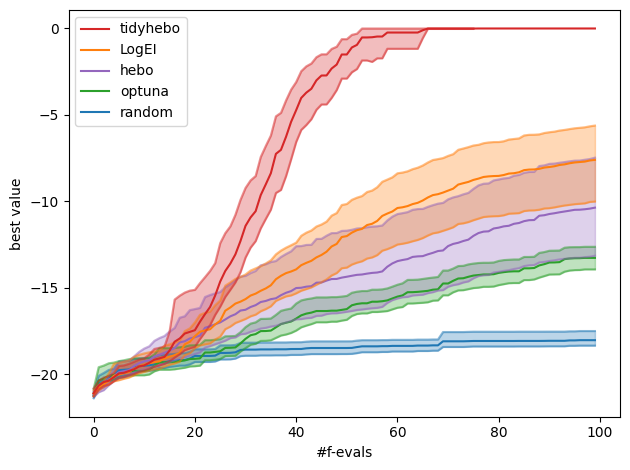

In [4]:
import matplotlib.pyplot as plt

ax = plt.gca()


plot_selection_result(random_res, ax, budget=100, label="random", color="tab:blue")
plot_selection_result(optuna_res, ax, budget=100, label="optuna", color="tab:green")
plot_selection_result(hebo_res, ax, budget=100, label="hebo", color="tab:purple")
plot_selection_result(qlogei_res, ax, budget=100, label="LogEI", color="tab:orange")
plot_selection_result(tidyhebo_res, ax, budget=100, label="tidyhebo", color="tab:red")



ax.set_xlabel("#f-evals")
ax.set_ylabel("best value")

ax.figure.tight_layout()

handles, labels = ax.get_legend_handles_labels()
ax.legend(reversed(handles), reversed(labels));

Это повод сравниться с Zombi